In [ ]:
# !pip install catboost

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
import statsmodels.api as sm


from scipy.optimize import curve_fit
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor
from xgboost import XGBRegressor

from sklearn.pipeline import Pipeline
from time import time
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [ ]:
data = pd.read_csv('/content/cansat-test.csv')
data.columns = data.columns.str.strip().str.lower()
data.head(4)

,time,temperature,humidity,pressure,altitude,velocity
0,0.0,37.67,23.14,979.12,0.00,0.0
1,0.5,37.67,23.11,979.11,-0.01,0.0
2,1.0,37.67,23.08,979.11,-0.01,0.0
3,1.5,37.67,23.06,979.12,-0.01,0.0


In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1057 entries, 0 to 1056
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   time         1057 non-null   float64
 1   temperature  1057 non-null   float64
 2   humidity     1057 non-null   float64
 3   pressure     1057 non-null   float64
 4   altitude     1057 non-null   float64
 5   velocity     1057 non-null   float64
dtypes: float64(6)
memory usage: 49.7 KB


In [ ]:
data.describe().T

,count,mean,std,min,25%,50%,75%,max
time,1057.0,266.251088,153.940771,0.00,133.10,266.20,399.40,532.50
temperature,1057.0,38.353519,0.484012,37.66,37.90,38.47,38.64,39.38
humidity,1057.0,23.967427,0.744217,22.29,23.46,24.07,24.50,25.53
pressure,1057.0,978.634636,1.693117,971.49,979.07,979.10,979.29,979.34
altitude,1057.0,4.135289,13.186295,-1.82,-0.88,0.17,0.37,59.51
velocity,1057.0,-0.001485,0.642710,-3.38,-0.01,0.00,0.01,1.99


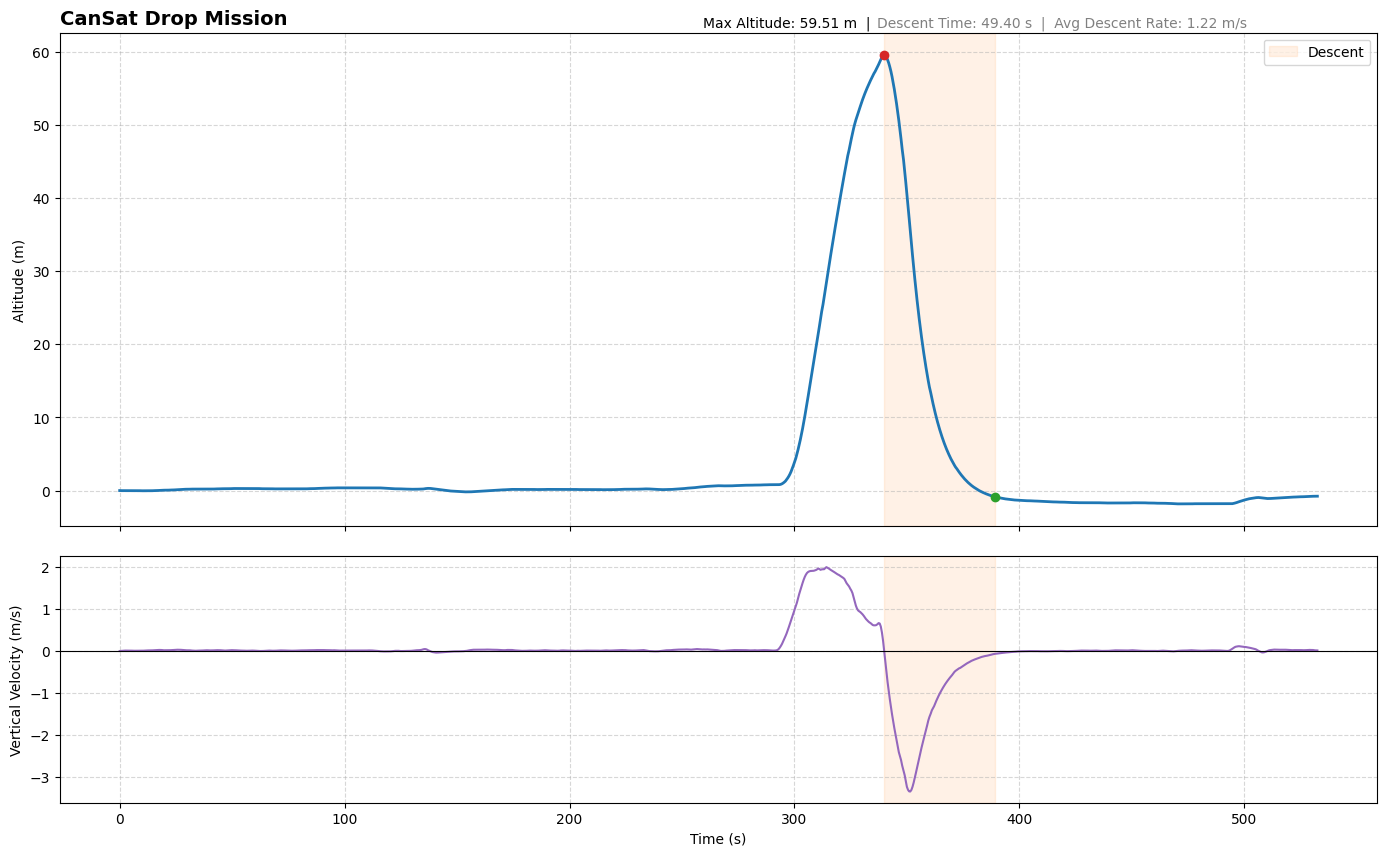

(<Figure size 1700x1000 with 2 Axes>,
 (<Axes: title={'left': 'CanSat Drop Mission'}, ylabel='Altitude (m)'>,
  <Axes: xlabel='Time (s)', ylabel='Vertical Velocity (m/s)'>))

In [ ]:
def plot_cansat_flight(data, time_col='time', alt_col='altitude', smooth_window=5, landing_tol=1.0, save_path=None):
  """
  plot altitude and vertical velocity for a CanSat drop mission.
  smooth_window : samples for the rolling mean on velocity (1 = no smoothing)
  landing_tol : meters above the minimum altitude counted as 'landed'
  """

  df = (
      data[[time_col, alt_col]]
      .dropna()
      .sort_values(time_col)
      .reset_index(drop=True)
  )

  t = df[time_col].to_numpy()
  alt = df[alt_col].to_numpy()

  # vertical velocity (m/s), lightly smoothed to time sensor noise
  vel = pd.Series(np.gradient(alt, t)).rolling(
      smooth_window, center=True, min_periods=1
  ).mean().to_numpy()

  i_peak = alt.argmax()
  landed = np.where(alt[i_peak:] <= alt.min() + landing_tol)[0]
  i_land = i_peak + (landed[0] if landed.size else len(alt) - 1 - i_peak)
  descent_time = t[i_land] - t[i_peak]
  avg_descent = (alt[i_peak] - alt[i_land]) / descent_time if descent_time > 0 else np.nan



  fig, (ax1, ax2) = plt.subplots(
      2, 1, figsize=(17,10),
      sharex=True, gridspec_kw={'height_ratios': [2,1],
                                'hspace': 0.08}
  )


  # altitude
  ax1.plot(
      t, alt, color='tab:blue',
      linewidth=2
  )

  ax1.axvspan(
      t[i_peak], t[i_land],
      color='tab:orange',
      alpha=0.10, label='Descent'
  )

  ax1.scatter(
      t[i_peak], alt[i_peak],
      color='tab:red',
      zorder=5
  )

  ax1.scatter(
      t[i_land], alt[i_land],
      color='tab:green',
      zorder=5
  )

  ax1.annotate(
      f"Max Altitude: {alt[i_peak]:.2f} m  |",
      (t[i_peak], alt[i_peak]),
      xytext=(-10, 20),
      textcoords='offset points',
      ha='right'
  )

  ax1.set_ylabel('Altitude (m)')
  ax1.set_title('CanSat Drop Mission', fontsize=14, fontweight='bold', loc='left')
  ax1.text(
      0.62, 1.012, f'Descent Time: {descent_time:.2f} s  |  Avg Descent Rate: {avg_descent:.2f} m/s',
      transform=ax1.transAxes, fontsize=10, color='gray'
  )

  ax1.grid(
      True, linestyle='--', alpha=0.5
  )

  ax1.legend(loc='upper right')


  # vertical velocity
  ax2.plot(
      t, vel,
      color='tab:purple',
      linewidth=1.5
  )

  ax2.axhline(
      0, color='black', linewidth=0.8
  )

  ax2.axvspan(
      t[i_peak], t[i_land],
      color='tab:orange', alpha=0.10
  )

  ax2.set_xlabel('Time (s)')
  ax2.set_ylabel('Vertical Velocity (m/s)')
  ax2.grid(
      True, linestyle='--', alpha=0.5
  )


  if save_path:
    fig.savefig(save_path, dpi=300, bbox_inches='tight')
  plt.show()
  return fig, (ax1, ax2)

plot_cansat_flight(data, save_path='cansat_flight.png')

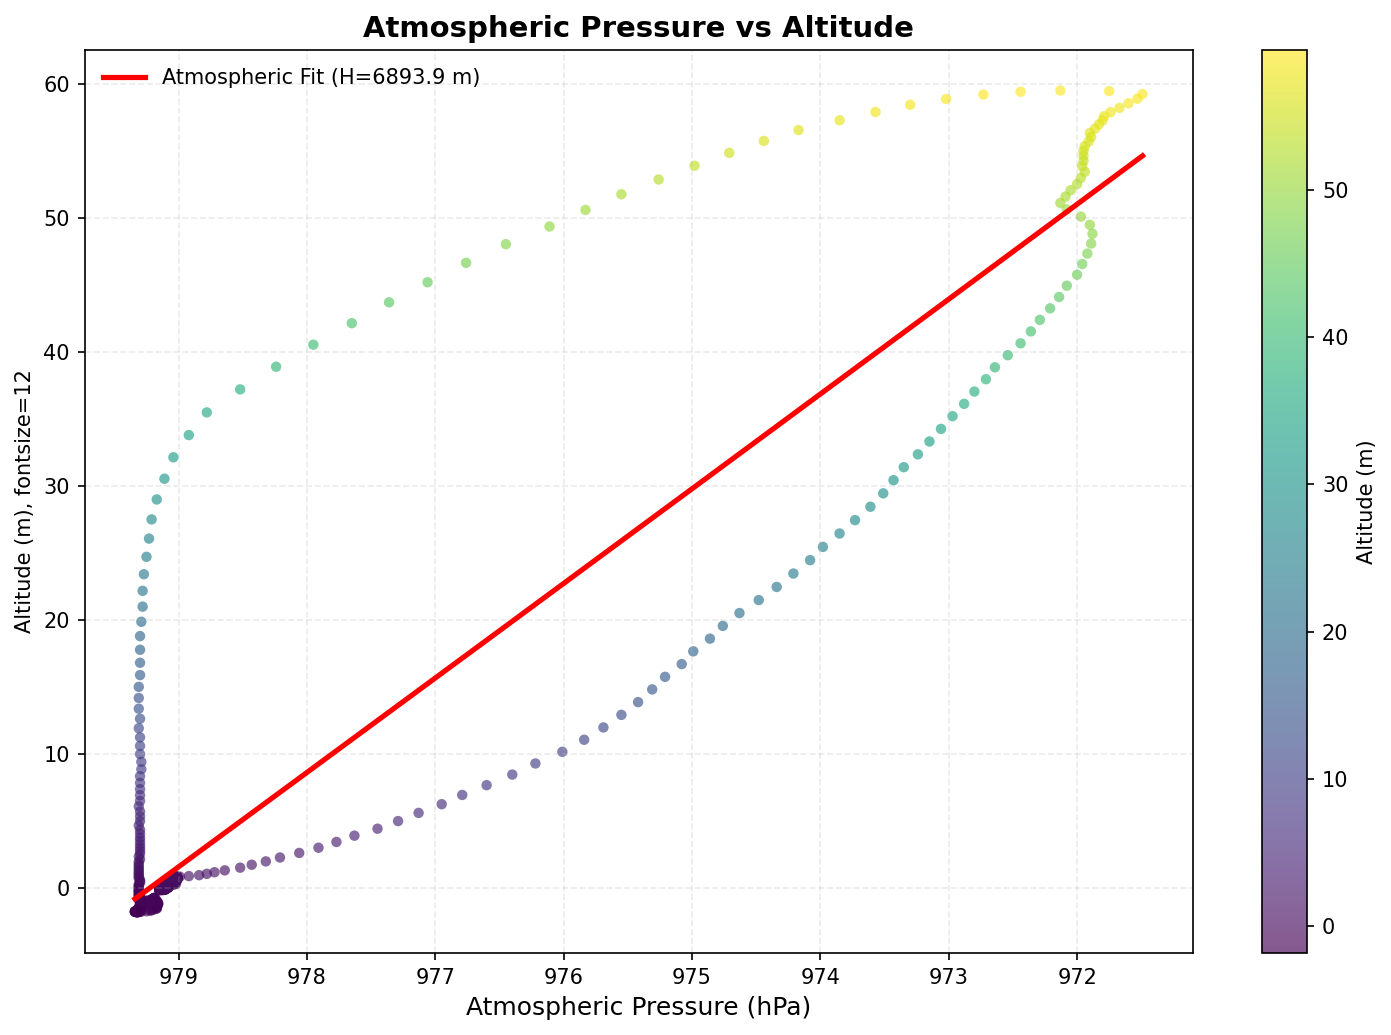

In [ ]:
df = data[['pressure', 'altitude']].dropna()
df = df[df['pressure'] > 0]
pressure = df['pressure'].values
altitude = df['altitude'].values


# exponensial atmospheric model
def atmospheric_model(p, H, h0):
  return h0 - H * np.log(p / 1013.25)

# fit model
params, _ = curve_fit(
    atmospheric_model,
    pressure, altitude,
    p0=[8000, 0]
)

H, h0 = params

# smooth curve
p_fit = np.linspace(pressure.min(), pressure.max(), 300)
alt_fit = atmospheric_model(p_fit, H, h0)

fig, ax = plt.subplots(figsize=(10,7), dpi=150)

scatter = ax.scatter(
    pressure, altitude, c=altitude,
    cmap='viridis', s=25, alpha=0.65,
    edgecolors='none',
)

ax.plot(
    p_fit, alt_fit, color='red',
    linewidth=2.5, label=f'Atmospheric Fit (H={H:.1f} m)'
)


# Atmospheric Convention
ax.invert_xaxis()
ax.set_xlabel('Atmospheric Pressure (hPa)', fontsize=12)
ax.set_ylabel('Altitude (m), fontsize=12')
ax.set_title(
    'Atmospheric Pressure vs Altitude',
    fontsize=14,
    fontweight='bold'
)


ax.grid(alpha=0.25, linestyle='--')
ax.legend(frameon=False)
cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label('Altitude (m)')
plt.tight_layout()
plt.show()

In [ ]:
print(f"Estimated Scale Height: {H:.5f} m")

Estimated Scale Height: 6893.91515 m


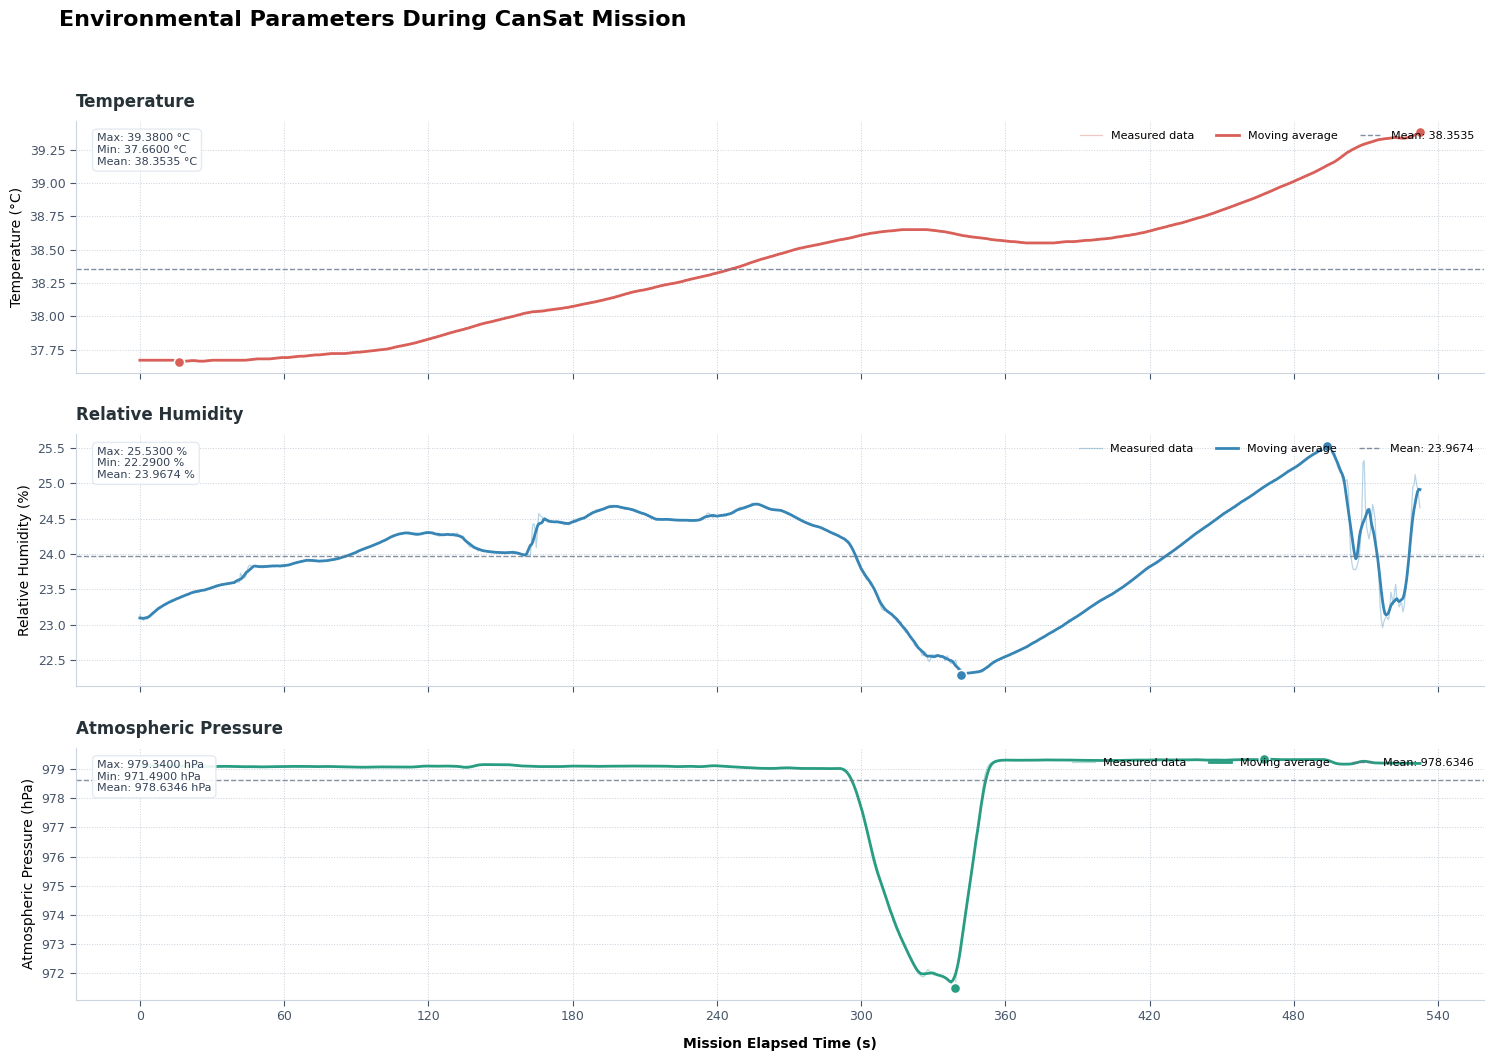

In [ ]:
df = data.copy()
df = df.sort_values('time').reset_index(drop=True)



# Sensor configuration
sensors = [
    {
        'column': 'temperature',
        'title': 'Temperature',
        'unit': '°C',
        'color': '#D95F59'
    },
    {
        'column': 'humidity',
        'title': 'Relative Humidity',
        'unit': '%',
        'color': '#3685B5'
    },
    {
        'column': 'pressure',
        'title': 'Atmospheric Pressure',
        'unit': 'hPa',
        'color': '#299D82'
    }
]

# Smoothing window
window = 10


plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'font.size': 10,
    'axes.titlesize': 12,
    'axes.titleweight': 'bold',
    'axes.labelsize': 10,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'legend.fontsize': 8,
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'savefig.dpi': 300
})


fig, axs = plt.subplots(
    3, 1,
    figsize=(16, 11),
    sharex=True
)

fig.suptitle(
    'Environmental Parameters During CanSat Mission',
    fontsize=16,
    fontweight='bold',
    x=0.08,
    ha='left',
    y=0.98
)


for ax, sensor in zip(axs, sensors):

    x = df['time']
    y = df[sensor['column']]

    # Ignore missing values in statistics
    valid = y.dropna()

    if valid.empty:
        ax.set_title(sensor['title'], loc='left')
        ax.text(
            0.5, 0.5, 'No valid measurements',
            transform=ax.transAxes,
            ha='center'
        )
        continue

    # Moving average
    smooth = y.rolling(
        window=window,
        center=True,
        min_periods=1
    ).mean()

    mean_value = valid.mean()
    max_value = valid.max()
    min_value = valid.min()

    max_idx = valid.idxmax()
    min_idx = valid.idxmin()

    # Raw measurements
    ax.plot(
        x, y,
        color=sensor['color'],
        linewidth=0.9,
        alpha=0.35,
        label='Measured data'
    )

    # Smoothed measurements
    ax.plot(
        x, smooth,
        color=sensor['color'],
        linewidth=2,
        label='Moving average'
    )

    # Mean reference line
    ax.axhline(
        mean_value,
        color='#64748B',
        linestyle='--',
        linewidth=1,
        alpha=0.8,
        label=f'Mean: {mean_value:.4f}'
    )

    # Maximum and minimum markers
    ax.scatter(
        [x.loc[max_idx], x.loc[min_idx]],
        [max_value, min_value],
        color=sensor['color'],
        edgecolor='white',
        linewidth=1.2,
        s=55,
        zorder=5
    )

    # Titles and labels
    ax.set_title(
        sensor['title'],
        loc='left',
        pad=10,
        color='#263238'
    )

    ax.set_ylabel(
        f'{sensor["title"]} ({sensor["unit"]})'
    )

    # Statistics annotation
    stats_text = (
        f'Max: {max_value:.4f} {sensor["unit"]}\n'
        f'Min: {min_value:.4f} {sensor["unit"]}\n'
        f'Mean: {mean_value:.4f} {sensor["unit"]}'
    )

    ax.text(
        0.015, 0.95,
        stats_text,
        transform=ax.transAxes,
        verticalalignment='top',
        fontsize=8,
        color='#334155',
        bbox=dict(
            boxstyle='round,pad=0.4',
            facecolor='white',
            edgecolor='#E2E8F0',
            alpha=0.9
        )
    )

    # Grid and axes
    ax.grid(
        True,
        linestyle=':',
        linewidth=0.7,
        color='#94A3B8',
        alpha=0.5
    )

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    ax.spines['left'].set_color('#CBD5E1')
    ax.spines['bottom'].set_color('#CBD5E1')

    ax.tick_params(
        axis='both',
        direction='out',
        length=4,
        colors='#475569'
    )

    # Legend
    ax.legend(
        loc='upper right',
        frameon=False,
        ncol=3
    )


axs[-1].set_xlabel(
    'Mission Elapsed Time (s)',
    fontweight='bold',
    labelpad=10
)

axs[-1].xaxis.set_major_locator(
    ticker.MaxNLocator(10)
)


fig.tight_layout(
    rect=[0.04, 0.02, 0.98, 0.95],
    h_pad=2.0
)

fig.savefig(
    'cansat_environmental_analysis.png',
    dpi=300,
    bbox_inches='tight',
    facecolor='white'
)

plt.show()


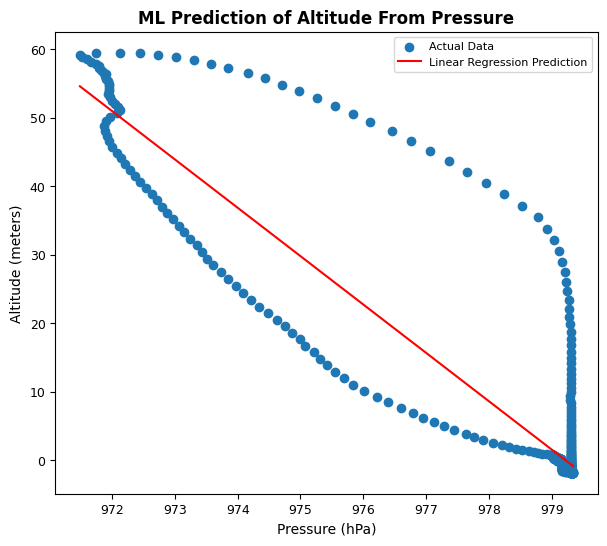

In [ ]:
X = data[['pressure']]
y = data['altitude']

# train model
lr_model = LinearRegression()
lr_model.fit(X,y)

# predictions
lr_pred = lr_model.predict(X)
lr_sorted_index = np.argsort(data['pressure'].values)
lr_pressure_sorted = data['pressure'].values[lr_sorted_index]
lr_pred_sorted = lr_pred[lr_sorted_index]

plt.figure(figsize=(7,6))
plt.scatter(data['pressure'], data['altitude'], label='Actual Data')
plt.plot(lr_pressure_sorted, lr_pred_sorted, color='red', label='Linear Regression Prediction')
plt.xlabel('Pressure (hPa)')
plt.ylabel('Altitude (meters)')
plt.title('ML Prediction of Altitude From Pressure')
plt.legend()
plt.show()

In [ ]:
X = data[['pressure']].copy()
y = data['altitude']

# remove missing and infinite values
valid = np.isfinite(X['pressure']) & np.isfinite(y)

X = X.loc[valid]
y = y.loc[valid]

print('Dataset Information')
print('=' * 60)
print(f'Total Observation : {len(X)}')
print(f'Features          : {list(X.columns)}')
print(f'Target            : altitude')

Dataset Information
Total Observation : 1057
Features          : ['pressure']
Target            : altitude


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.21, random_state=42)
print('\nData Splitting: ')
print('=' * 60)
print(f'Training Samples : {len(X_train)}')
print(f'Testing Samples  : {len(X_test)}')



Data Splitting: 
Training Samples : 835
Testing Samples  : 222


In [ ]:
# define regression models

models = {
    'Linear Regression': LinearRegression(),
    'Polynomial Regression': Pipeline(
        [
            ('poly', PolynomialFeatures(degree=2, include_bias=False)),
            ('linear', LinearRegression())
        ]
    ),

    'Random Forest': RandomForestRegressor(
        n_estimators=300, max_depth=10, min_samples_split=5,
        min_samples_leaf=2, max_features=0.8, bootstrap=True,
        random_state=42, n_jobs=-1
    ),

    'Gradient Boosting': GradientBoostingRegressor(
        n_estimators=300, learning_rate=0.03, max_depth=3,
        min_samples_split=5, min_samples_leaf=2, subsample=0.8,
        loss='squared_error', random_state=42
    ),

    'CatBoost': CatBoostRegressor(
        iterations=650, learning_rate=0.03, depth=6,
        loss_function='RMSE', random_seed=42, verbose=False
    ),

    'LightGBM': LGBMRegressor(
        n_estimators=500, learning_rate=0.03, max_depth=-1,
        num_leaves=31, objective='regression', random_state=42,
        verbosity=-1
    ),

    'XGBoost': XGBRegressor(
        n_estimators=500, learning_rate=0.03, max_depth=6,
        min_child_weight=3, subsample=0.8, colsample_bytree=0.8,
        reg_alpha=0.1, reg_lambda=1.0, objective='reg:squarederror',
        eval_metric='rmse', random_state=42, n_jobs=-1
    )
}

In [ ]:
# evaluation function

def evaluate_model(y_true, y_pred):
  return {
      'MAE': mean_absolute_error(
          y_true,
          y_pred
      ),

      'RMSE': np.sqrt(
          mean_squared_error(
              y_true,
              y_pred
          )
      ),

      'R2': r2_score(
          y_true,
          y_pred
      )
  }



# generate pressure range
pressure_range = np.linspace(
    X['pressure'].min(),
    X['pressure'].max(),
    500
)

pressure_range_df = pd.DataFrame(
    {
        'pressure': pressure_range
    }
)



# train and evaluation all 8 models
results = []
predictions = {}
curve_predictions = {}
trained_models = {}
training_times = {}

all_model_names = [
    'Linear Regression', 'Polynomial Regression', 'Statsmodels OLS',
    'Random Forest', 'Gradient Boosting', 'CatBoost', 'LightGBM',
    'XGBoost'
]


for name in all_model_names:
  print(f'\nTraining: {name}')
  start_time = time()

  # statsmodels OLS
  if name == 'Statsmodels OLS':
    X_train_model = sm.add_constant(
        X_train, has_constant='add'
    )

    X_test_model = sm.add_constant(
        X_test, has_constant='add'
    )

    X_curve_model = sm.add_constant(
        pressure_range_df,
        has_constant='add'
    )

    model = sm.OLS(
        y_train,
        X_train_model
    ).fit()

    y_train_pred = model.predict(X_train_model)
    y_test_pred = model.predict(X_test_model)
    curve_pred = model.predict(X_curve_model)

  else:
    model = models[name]
    model.fit(X_train, y_train)
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)
    curve_pred = model.predict(pressure_range_df)


  # evaluate training and testing
  train_metrics = evaluate_model(y_train, y_train_pred)
  test_metrics = evaluate_model(y_test, y_test_pred)
  elapsed_time = time() - start_time


# save evaluation results
  results.append(
      {
          'Model': name,
          'Train MAE': train_metrics['MAE'],
          'Test MAE': test_metrics['MAE'],
          'Train RMSE': train_metrics['RMSE'],
          'Test RMSE': test_metrics['RMSE'],
          'Train R2': train_metrics['R2'],
          'Test R2': test_metrics['R2'],
          'Training Time (s)': elapsed_time
      }
  )


  # save predictions
  predictions[name] = {
      'train': y_train_pred,
      'test': y_test_pred
  }
  curve_predictions[name] = curve_pred
  trained_models[name] = model
  training_times[name] = elapsed_time

  print(f'\nTrain R2  : {train_metrics['R2']:.4f}')
  print(f'Test R2   : {test_metrics['R2']:.4f}')
  print(f'Test MAE  : {test_metrics['MAE']:.4f}')
  print(f'Test RMSE : {test_metrics['RMSE']:.4f}')


Training: Linear Regression

Train R2  : 0.8276
Test R2   : 0.7928
Test MAE  : 2.1246
Test RMSE : 5.1121

Training: Polynomial Regression

Train R2  : 0.8276
Test R2   : 0.7927
Test MAE  : 2.1255
Test RMSE : 5.1128

Training: Statsmodels OLS

Train R2  : 0.8276
Test R2   : 0.7928
Test MAE  : 2.1246
Test RMSE : 5.1121

Training: Random Forest

Train R2  : 0.8742
Test R2   : 0.7174
Test MAE  : 2.1495
Test RMSE : 5.9700

Training: Gradient Boosting

Train R2  : 0.8964
Test R2   : 0.6840
Test MAE  : 2.2277
Test RMSE : 6.3128

Training: CatBoost

Train R2  : 0.8944
Test R2   : 0.7040
Test MAE  : 2.1729
Test RMSE : 6.1100

Training: LightGBM

Train R2  : 0.8454
Test R2   : 0.7920
Test MAE  : 1.8691
Test RMSE : 5.1217

Training: XGBoost

Train R2  : 0.9298
Test R2   : 0.6549
Test MAE  : 2.2294
Test RMSE : 6.5968


In [ ]:
comparison = pd.DataFrame(results)
comparison = comparison.sort_values(
    by='Test RMSE',
    ascending=True
).reset_index(drop=True)

comparison.insert(
    0, 'Rank',
    range(1, len(comparison) + 1)
)


print(comparison.round(4).to_string(index=False))

 Rank                 Model  Train MAE  Test MAE  Train RMSE  Test RMSE  Train R2  Test R2  Training Time (s)
    1       Statsmodels OLS     2.4708    2.1246      5.6609     5.1121    0.8276   0.7928             0.0088
    2     Linear Regression     2.4708    2.1246      5.6609     5.1121    0.8276   0.7928             0.0168
    3 Polynomial Regression     2.4720    2.1255      5.6609     5.1128    0.8276   0.7927             0.0119
    4              LightGBM     2.1620    1.8691      5.3614     5.1217    0.8454   0.7920             0.1367
    5         Random Forest     1.9459    2.1495      4.8365     5.9700    0.8742   0.7174             0.9080
    6              CatBoost     1.8323    2.1729      4.4307     6.1100    0.8944   0.7040             0.4039
    7     Gradient Boosting     1.7996    2.2277      4.3884     6.3128    0.8964   0.6840             0.3300
    8               XGBoost     1.4055    2.2294      3.6136     6.5968    0.9298   0.6549             0.1980


In [ ]:
best_model_name = comparison.iloc[0]['Model']
best_result = comparison.iloc[0]
best_model_rmse = best_result['Test RMSE']
best_model_mae = best_result['Test MAE']
best_model_r2 = best_result['Test R2']

print('\n' + '=' * 70)
print('Best Regression Model: ')
print('=' * 70)

print(f'Best Model:   {best_model_name}')
print(f'Test RMSE:    {best_model_rmse:.5f}')
print(f'Test MAE:     {best_model_mae:.5f}')
print(f'Test R2 Score: {best_model_r2:.5f}')


Best Regression Model: 
Best Model:   Statsmodels OLS
Test RMSE:    5.11211
Test MAE:     2.12460
Test R2 Score: 0.79277


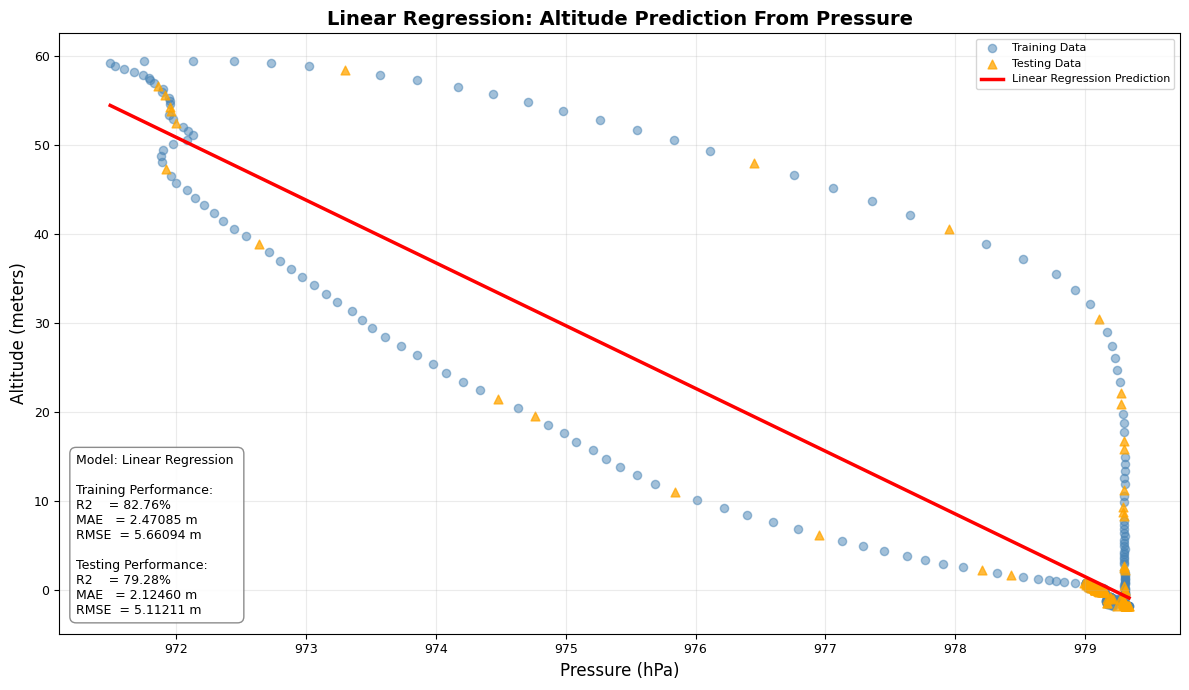

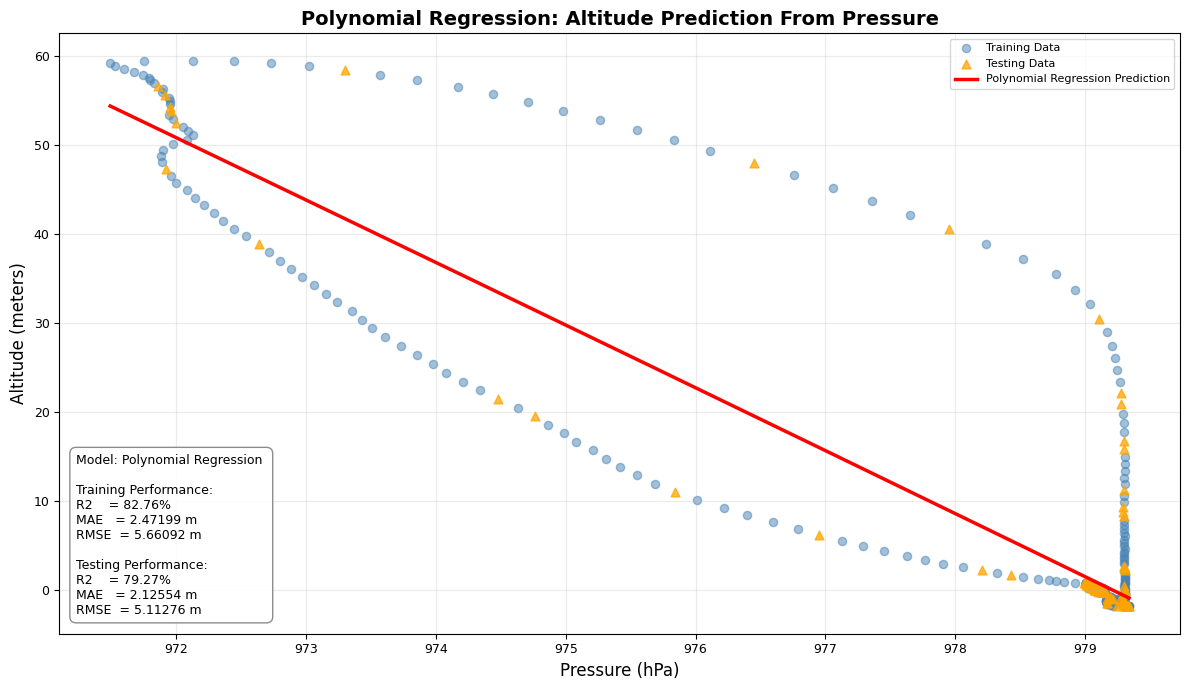

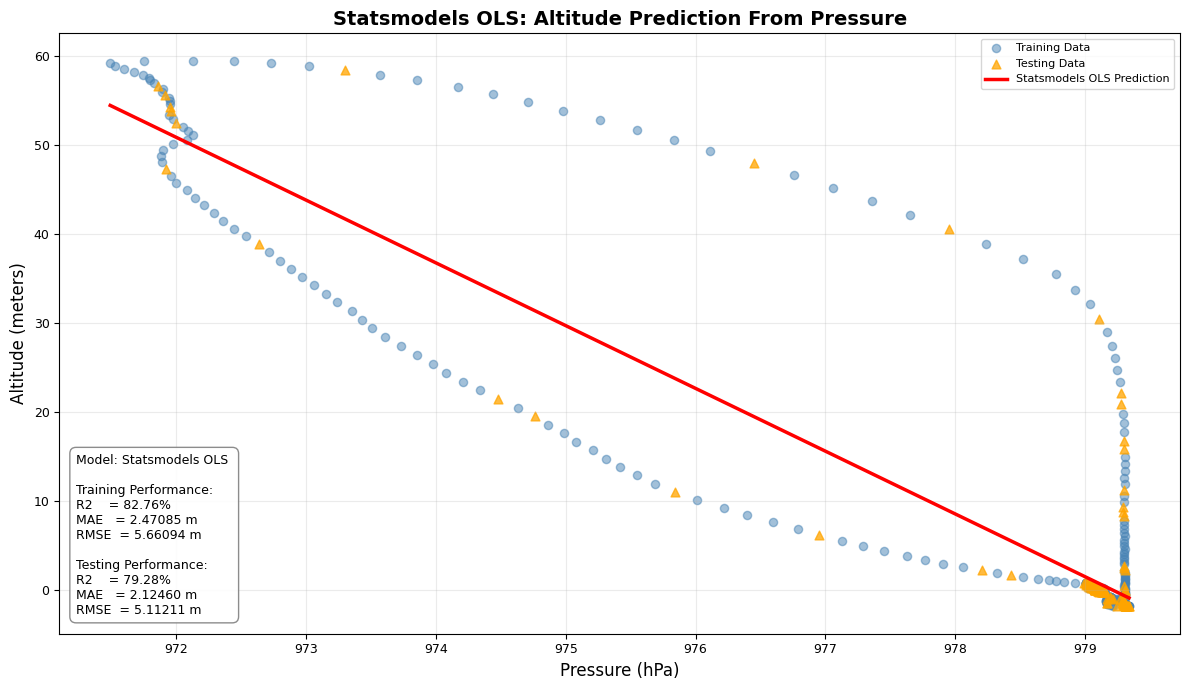

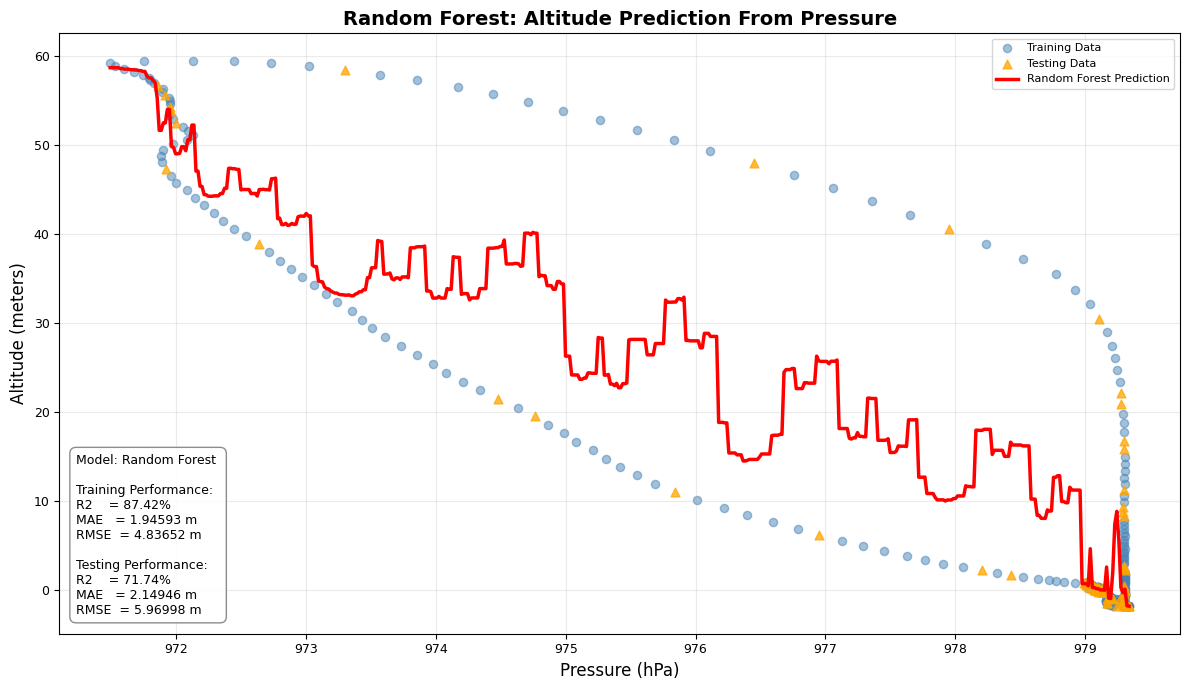

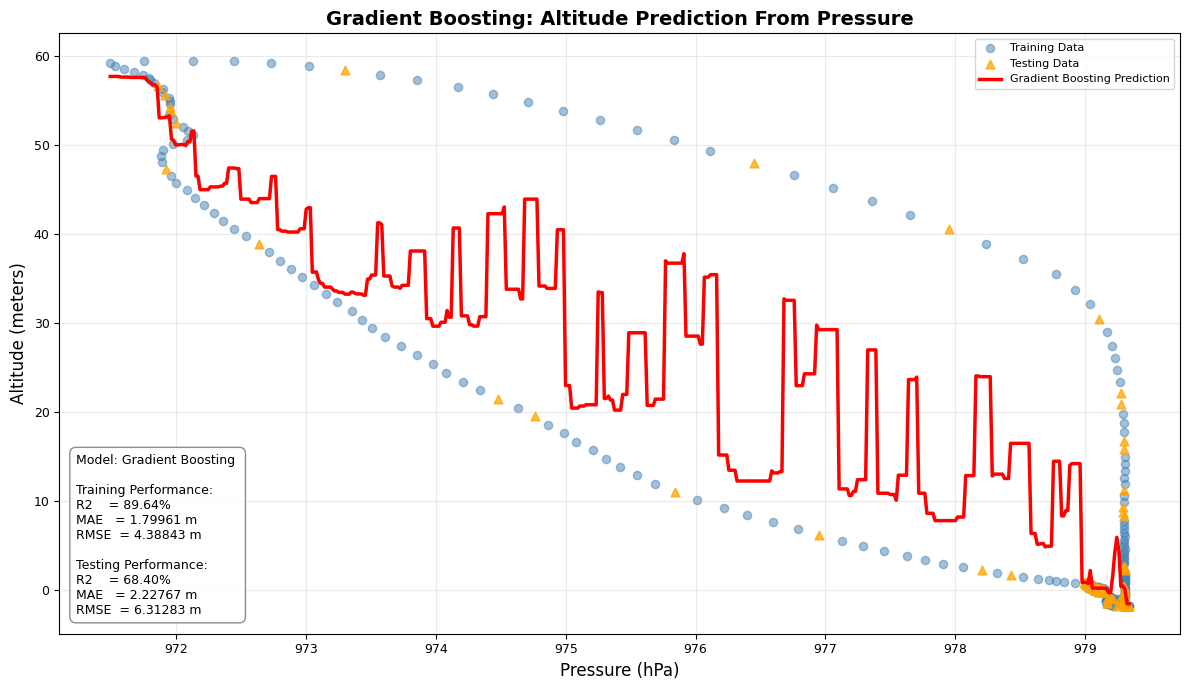

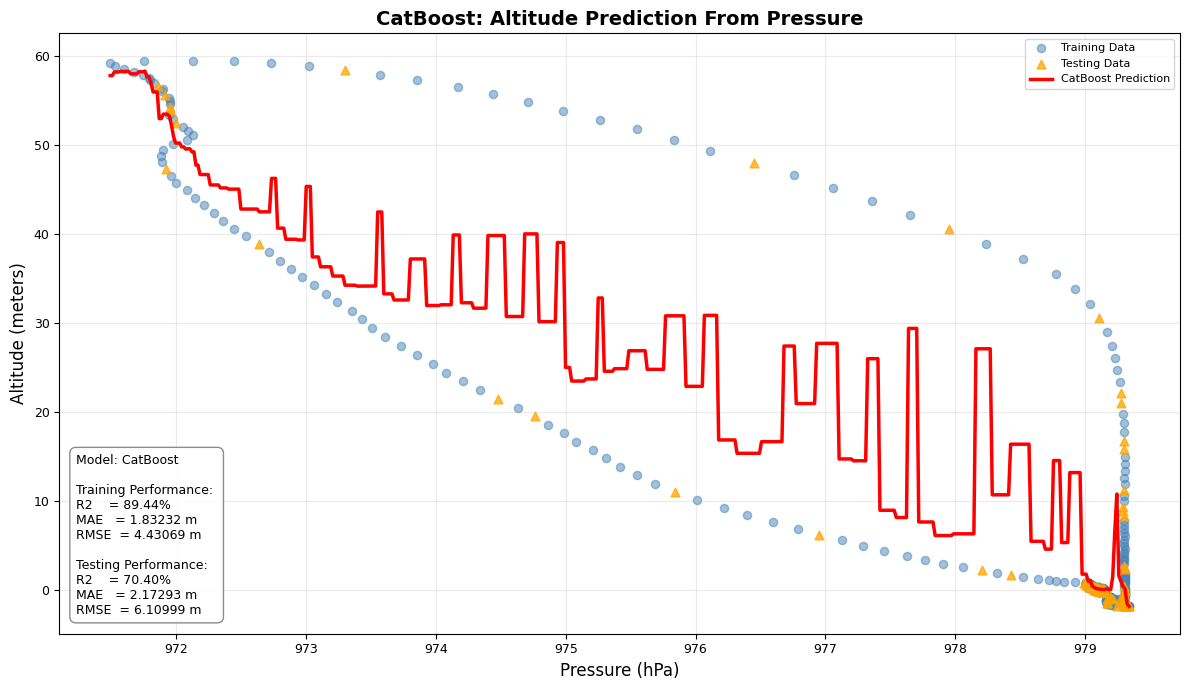

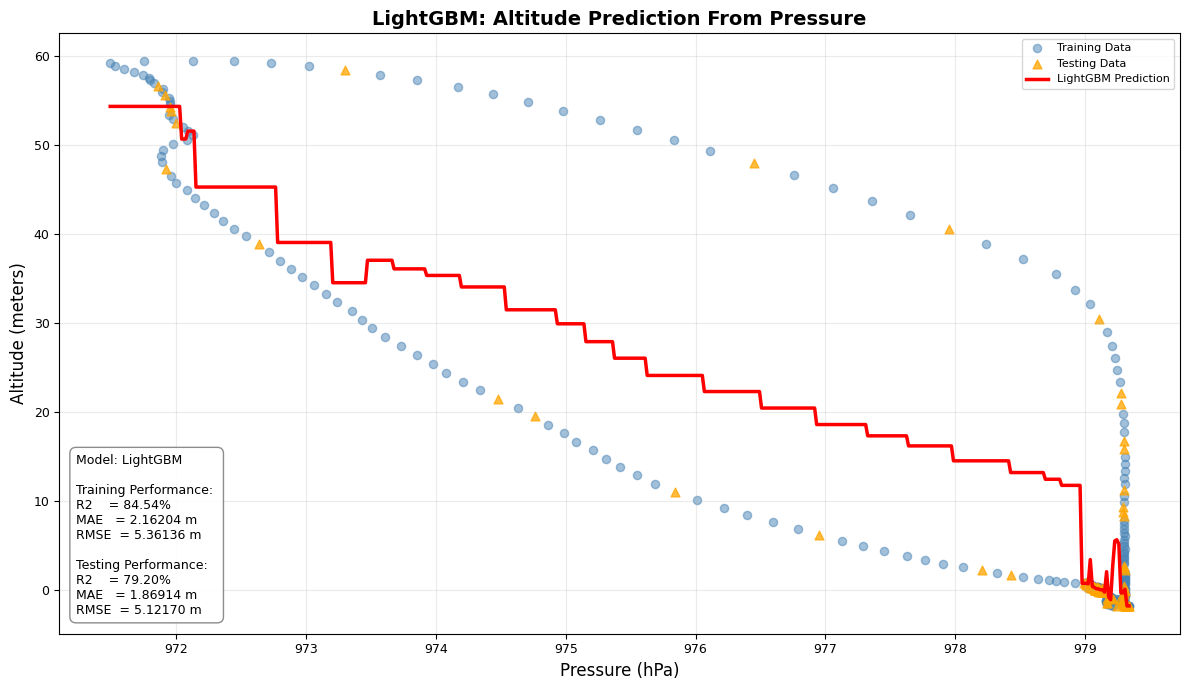

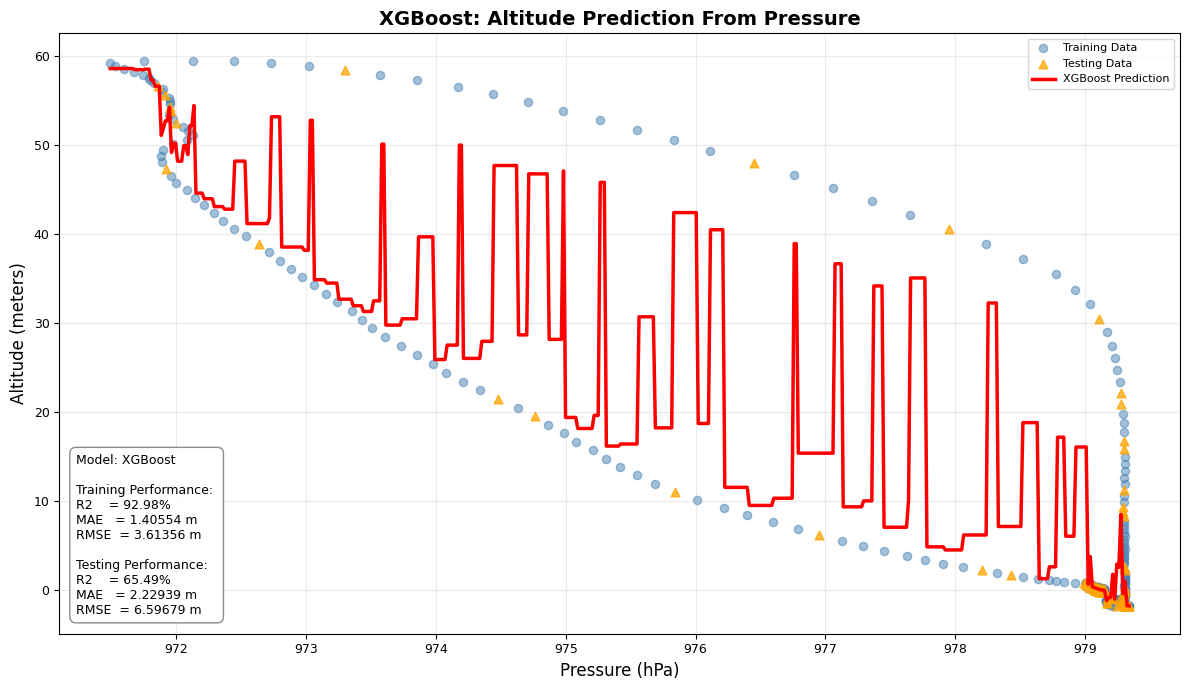

In [ ]:
for name in all_model_names:
  fig, ax = plt.subplots(figsize=(12,7))

  # training observations
  ax.scatter(
      X_train['pressure'], y_train,
      color='steelblue', alpha=0.50,
      s=35, label='Training Data'
  )

  # testing observation
  ax.scatter(
      X_test['pressure'], y_test,
      color='orange', alpha=0.75,
      s=40, marker='^',
      label='Testing Data'
  )

  # regression curve
  ax.plot(
      pressure_range, curve_predictions[name], color='red',
      linewidth=2.5, label=f'{name} Prediction'

  )

  # get model metrics
  model_result = comparison[
      comparison['Model'] == name
  ].iloc[0]


  # model information
  model_info = (
      f'Model: {name} \n\n'

      f'Training Performance: \n'
      f'R2    = {100 * model_result['Train R2']:.2f}%\n'
      f'MAE   = {model_result['Train MAE']:.5f} m\n'
      f'RMSE  = {model_result['Train RMSE']:.5f} m\n\n'

      f'Testing Performance:\n'
      f'R2    = {100 * model_result['Test R2']:.2f}%\n'
      f'MAE   = {model_result['Test MAE']:.5f} m\n'
      f'RMSE  = {model_result['Test RMSE']:.5f} m'
  )


  ax.text(
      0.015, 0.3, model_info,
      transform=ax.transAxes,
      fontsize=9, verticalalignment='top',
      bbox=dict(
          boxstyle='round,pad=0.5',
          facecolor='white',
          edgecolor='gray',
          alpha=0.9
      )
  )


  ax.set_xlabel('Pressure (hPa)', fontsize=12)
  ax.set_ylabel('Altitude (meters)', fontsize=12)
  ax.set_title(f'{name}: Altitude Prediction From Pressure', fontsize=14, fontweight='bold')
  ax.legend(loc='best')
  ax.grid(alpha=0.25)
  plt.tight_layout()
  plt.show()

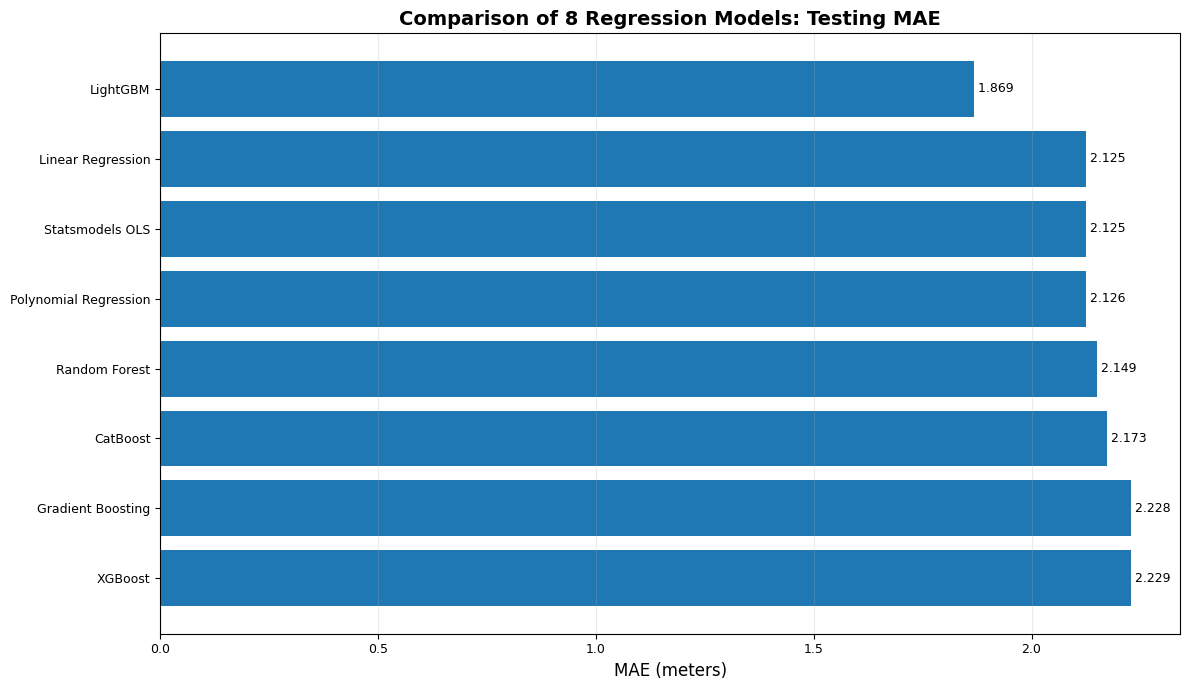

In [ ]:
plot_mae = comparison.sort_values(
    'Test MAE',
    ascending=True
)

fig, ax = plt.subplots(figsize=(12,7))
bars = ax.barh(plot_mae['Model'], plot_mae['Test MAE'])
ax.invert_yaxis()
ax.set_xlabel('MAE (meters)', fontsize=12)
ax.set_title('Comparison of 8 Regression Models: Testing MAE',
             fontsize=14, fontweight='bold')

for bar in bars:
  width = bar.get_width()
  ax.text(width, bar.get_y() + bar.get_height() / 2,
          f' {width:.3f}',
          va='center', fontsize=9)


ax.grid(axis='x', alpha=0.25)
plt.tight_layout()
plt.show()

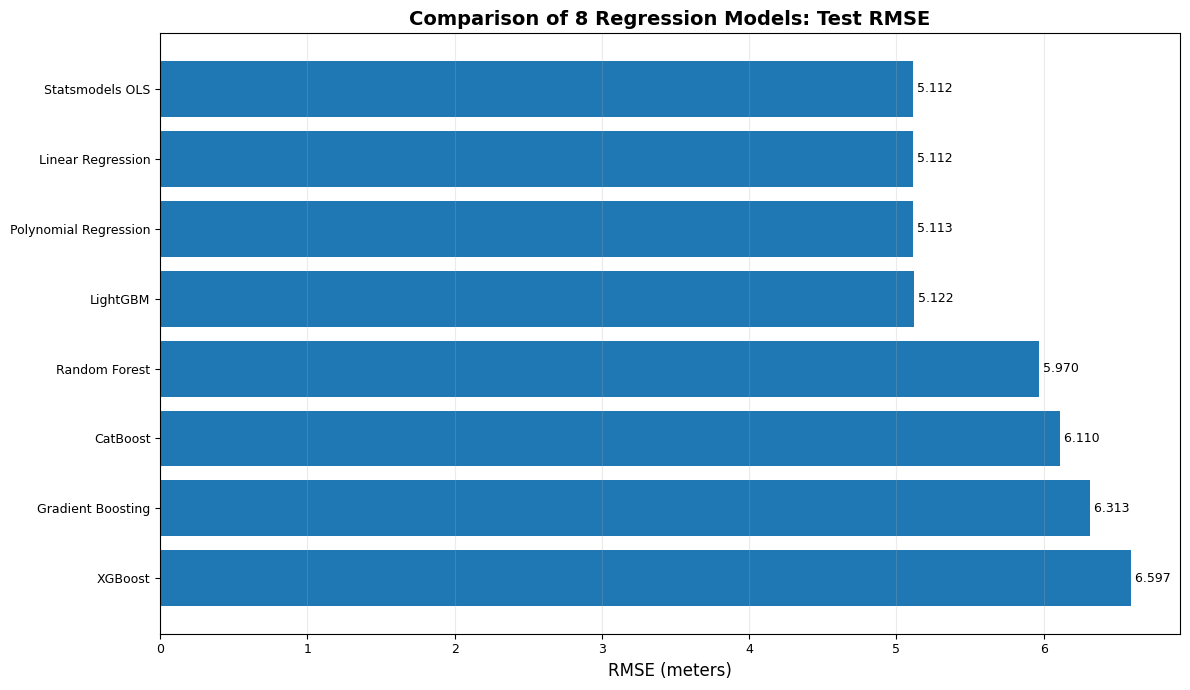

In [ ]:
plot_rmse = comparison.sort_values(
    'Test RMSE',
    ascending=True
)

fig, ax = plt.subplots(figsize=(12, 7))

bars = ax.barh(
    plot_rmse['Model'],
    plot_rmse['Test RMSE']
)

ax.invert_yaxis()

ax.set_xlabel(
    'RMSE (meters)',
    fontsize=12
)

ax.set_title(
    'Comparison of 8 Regression Models: Test RMSE',
    fontsize=14,
    fontweight='bold'
)

for bar in bars:

    width = bar.get_width()

    ax.text(
        width,
        bar.get_y() + bar.get_height() / 2,
        f' {width:.3f}',
        va='center',
        fontsize=9
    )

ax.grid(axis='x', alpha=0.25)

plt.tight_layout()
plt.show()

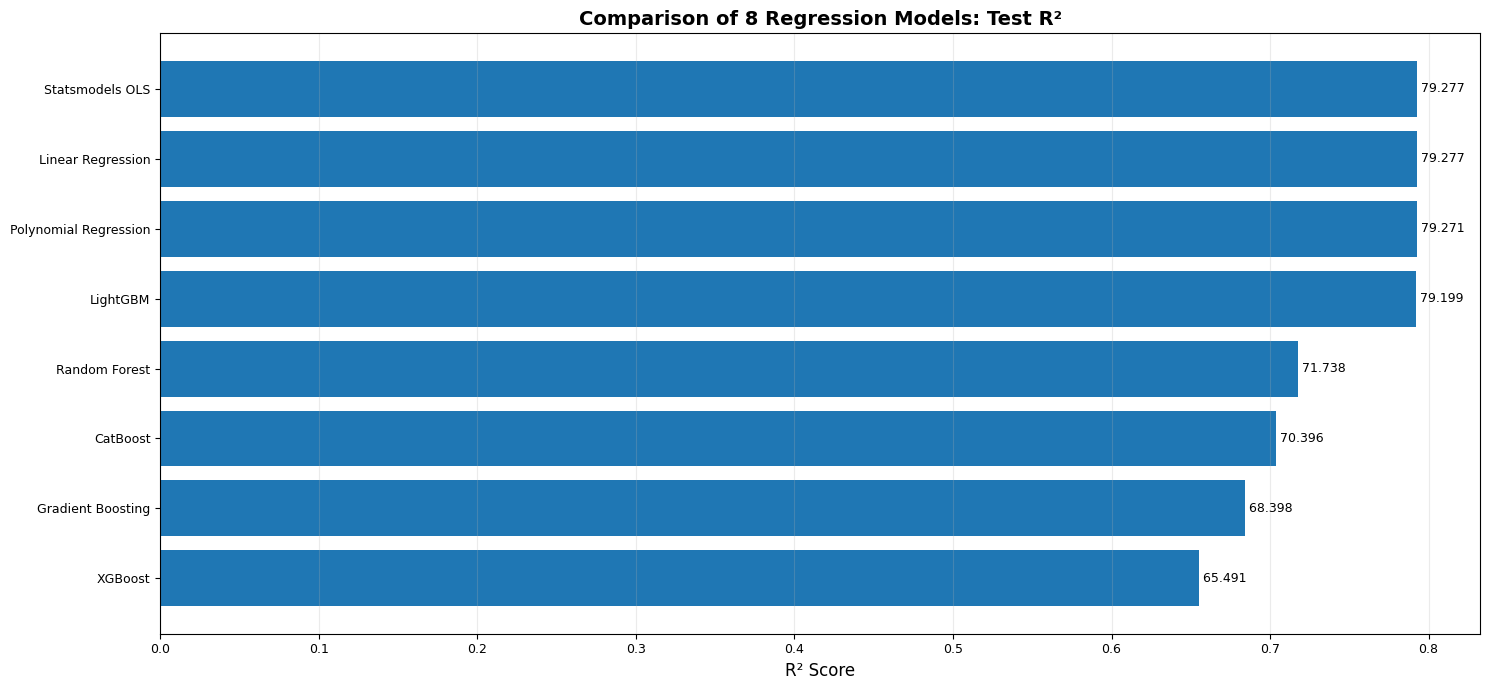

In [ ]:
plot_r2 = comparison.sort_values(
    'Test R2',
    ascending=False
)

fig, ax = plt.subplots(figsize=(15, 7))

bars = ax.barh(
    plot_r2['Model'],
    plot_r2['Test R2']
)

ax.invert_yaxis()

ax.set_xlabel(
    'R² Score',
    fontsize=12
)

ax.set_title(
    'Comparison of 8 Regression Models: Test R²',
    fontsize=14,
    fontweight='bold'
)

for bar in bars:

    width = bar.get_width()

    ax.text(
        width,
        bar.get_y() + bar.get_height() / 2,
        f' {100 * width:.3f}',
        va='center',
        fontsize=9
    )

ax.grid(axis='x', alpha=0.25)

plt.tight_layout()
plt.show()

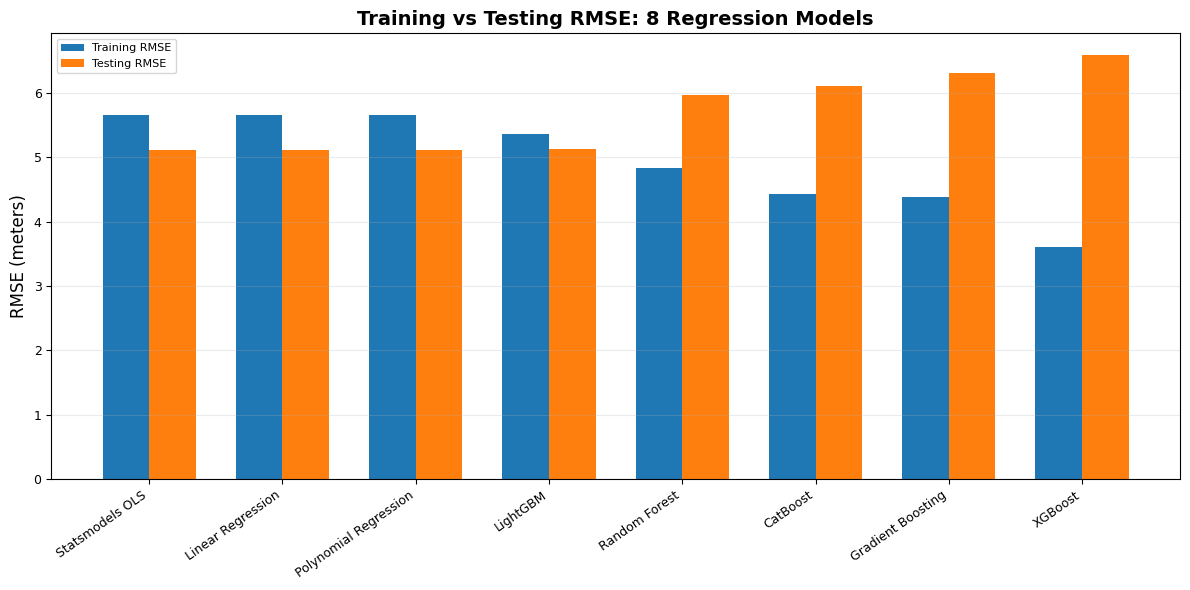

In [ ]:
fig, ax = plt.subplots(figsize=(12, 6))

x = np.arange(len(comparison))
width = 0.35

ax.bar(
    x - width / 2,
    comparison['Train RMSE'],
    width,
    label='Training RMSE'
)

ax.bar(
    x + width / 2,
    comparison['Test RMSE'],
    width,
    label='Testing RMSE'
)

ax.set_xticks(x)

ax.set_xticklabels(
    comparison['Model'],
    rotation=35,
    ha='right'
)

ax.set_ylabel(
    'RMSE (meters)',
    fontsize=12
)

ax.set_title(
    'Training vs Testing RMSE: 8 Regression Models',
    fontsize=14,
    fontweight='bold'
)

ax.legend()
ax.grid(axis='y', alpha=0.25)

plt.tight_layout()
plt.show()

In [ ]:
comparison.to_csv(
    'regression_model_comparison.csv',
    index=False
)

# Export detailed predictions
prediction_data = pd.DataFrame({
    'Actual_Altitude': y_test
})

for name in all_model_names:

    prediction_data[name] = predictions[name]['test']

prediction_data.to_csv(
    'regression_model_predictions.csv'
)

print("\n" + "=" * 60)
print("EXPERIMENT COMPLETED")
print("=" * 60)

print("\nGenerated files:")
print("1. regression_model_comparison.csv")
print("2. regression_model_predictions.csv")

print("\nTotal models evaluated:", len(all_model_names))

print("\nBest model:", best_model_name)
print("Best Test RMSE:", round(best_model_rmse, 4))
print("Best Test MAE:", round(best_model_mae, 4))
print("Best Test R2:", round(best_model_r2, 4))


EXPERIMENT COMPLETED

Generated files:
1. regression_model_comparison.csv
2. regression_model_predictions.csv

Total models evaluated: 8

Best model: Statsmodels OLS
Best Test RMSE: 5.1121
Best Test MAE: 2.1246
Best Test R2: 0.7928


In [ ]:
test_pressures = pd.DataFrame(
    {
        'pressure': [978, 975, 972, 976, 977]
    }
)

prediction_comparison = test_pressures.copy()
for name in all_model_names:
  model = trained_models[name]

  if name == 'Statsmodels OLS':
    X_new = sm.add_constant(
        test_pressures,
        has_constant='add'
    )

    predicted = model.predict(X_new)

  else:
    predicted = model.predict(test_pressures)


  prediction_comparison[name] = predicted


print('Altitude Prediction Comparison: ')
print('=' * 80)
print(prediction_comparison.round(2).to_string(index=False))

Altitude Prediction Comparison: 
 pressure  Linear Regression  Polynomial Regression  Statsmodels OLS  Random Forest  Gradient Boosting  CatBoost  LightGBM   XGBoost
      978               8.58                   8.62             8.58          10.30               7.82      6.33     14.54  4.530000
      975              29.73                  29.80            29.73          26.31              23.01     25.03     29.94 19.420000
      972              50.88                  50.84            50.88          49.04              50.05     50.24     54.37 48.209999
      976              22.68                  22.75            22.68          28.02              28.55     22.90     24.13 42.430000
      977              15.63                  15.69            15.63          25.71              29.29     27.73     18.62 15.400000
